# 🧪 Hands-On Data Lab: Retail Sales Analysis

**Author:** Juhi Parnami &nbsp;|&nbsp; **Tools:** Python, Jupyter, pandas, NumPy, Matplotlib, Seaborn, SciPy

This notebook is a complete practical lab. It follows the three objectives of the assessment:

1. **Environment setup**: Python + Jupyter + required libraries
2. **Data manipulation**: cleaning, merging, filtering, grouping, pivoting
3. **Visualization and basic analysis**: charts, summary statistics, correlation, insights

> The data is **synthetic** (generated by `generate_data.py` with a fixed seed), so every result here is reproducible.

## 1. Environment setup
**Why first?** Results are only reproducible if we know exactly which versions produced them. This cell imports every library and prints their versions.

In [1]:
import json
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns

print(f"Python      : {platform.python_version()}")
print(f"NumPy       : {np.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"Seaborn     : {sns.__version__}")
print(f"SciPy       : {scipy.__version__}")

# Global display and plotting settings
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30
sns.set_theme(style="whitegrid", context="notebook")
PRIMARY, ACCENT, DARK = "#4F46E5", "#F97316", "#1E293B"

DATA_DIR, FIG_DIR = Path("data"), Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
results = {}   # key numbers are collected here and saved at the end

Python      : 3.12.3
NumPy       : 2.4.4
pandas      : 3.0.2
Matplotlib  : 3.10.8
Seaborn     : 0.13.2
SciPy       : 1.17.1


## 2. Load and inspect the data
**Why inspect first?** Never analyse data you have not looked at. We check shape, data types and missing values before doing anything else.

In [2]:
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
orders = pd.read_csv(DATA_DIR / "orders.csv")

for name, frame in [("customers", customers), ("products", products), ("orders", orders)]:
    print(f"{name:10s} -> {frame.shape[0]:>5} rows x {frame.shape[1]} columns")

customers  ->   400 rows x 4 columns
products   ->    20 rows x 5 columns
orders     ->  3015 rows x 7 columns


In [3]:
orders.head()

,order_id,customer_id,product_id,order_date,quantity,discount_pct,payment_method
0,O50000,C1213,P107,2025-03-14,2,0,UPI
1,O50001,C1135,P104,2025-05-13,1,10,Wallet
2,O50002,C1266,P113,2025-10-19,3,15,UPI
3,O50003,C1079,P104,2025-12-24,2,5,Card
4,O50004,C1039,P118,2025-04-09,1,5,UPI


In [4]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 3015 entries, 0 to 3014
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id        3015 non-null   str  
 1   customer_id     3015 non-null   str  
 2   product_id      3015 non-null   str  
 3   order_date      3015 non-null   str  
 4   quantity        3015 non-null   int64
 5   discount_pct    3015 non-null   int64
 6   payment_method  3015 non-null   str  
dtypes: int64(2), str(5)
memory usage: 165.0 KB


In [5]:
print("Missing values per table")
print("customers:", customers.isna().sum()[lambda s: s > 0].to_dict())
print("products :", products.isna().sum()[lambda s: s > 0].to_dict())
print("orders   :", orders.isna().sum()[lambda s: s > 0].to_dict())
print("\nDuplicate order rows:", orders.duplicated().sum())
print("City spellings      :", sorted(customers['city'].unique()))

Missing values per table
customers: {'age': 24}
products : {}
orders   : {}

Duplicate order rows: 15
City spellings      : ['Ahmedabad', 'BENGALURU', 'Bengaluru', 'DELHI', 'Delhi', 'HYDERABAD', 'Hyderabad', 'JAIPUR', 'Jaipur', 'KOLKATA', 'Kolkata', 'Mumbai', 'PUNE', 'Pune']


## 3. Data manipulation
### 3.1 Cleaning
Each fix below targets a problem found in section 2.

In [6]:
results["rows_raw"] = int(len(orders))

# (a) Remove exact duplicate orders
results["duplicates_removed"] = int(orders.duplicated().sum())
orders = orders.drop_duplicates().reset_index(drop=True)

# (b) Standardise text so 'JAIPUR' and 'Jaipur' become one category
customers["city"] = customers["city"].str.strip().str.title()

# (c) Convert text dates to real datetime values
orders["order_date"] = pd.to_datetime(orders["order_date"])

# (d) Fill missing ages with the median (robust to outliers)
results["missing_age"] = int(customers["age"].isna().sum())
customers["age"] = customers["age"].fillna(customers["age"].median())

results["rows_clean"] = int(len(orders))
print(f"Duplicates removed : {results['duplicates_removed']}")
print(f"Missing ages filled: {results['missing_age']}")
print(f"Cities now         : {sorted(customers['city'].unique())}")
print(f"Order rows         : {results['rows_raw']} -> {results['rows_clean']}")

Duplicates removed : 15
Missing ages filled: 24
Cities now         : ['Ahmedabad', 'Bengaluru', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai', 'Pune']
Order rows         : 3015 -> 3000


### 3.2 Merging tables
**Why merge?** Orders only hold IDs. Joining with `customers` and `products` gives us city, age, category and price in one table. We use a **left join** so no order is lost, then verify that nothing failed to match.

In [7]:
df = (
    orders
    .merge(customers, on="customer_id", how="left", validate="m:1")
    .merge(products, on="product_id", how="left", validate="m:1")
)
assert len(df) == len(orders), "merge changed the number of orders"
assert df[["city", "category"]].notna().all().all(), "some orders failed to match"
print("Merged shape:", df.shape)
df.head(3)

Merged shape: (3000, 14)


,order_id,customer_id,product_id,order_date,quantity,discount_pct,payment_method,city,age,gender,product_name,category,unit_price,cost_price
0,O50000,C1213,P107,2025-03-14,2,0,UPI,Kolkata,31.00,Male,Cotton Kurta,Fashion,999,450
1,O50001,C1135,P104,2025-05-13,1,10,Wallet,Jaipur,58.00,Male,Cotton T-Shirt,Fashion,599,250
2,O50002,C1266,P113,2025-10-19,3,15,UPI,Mumbai,57.00,Male,Matte Lipstick,Beauty,499,180


### 3.3 Creating new columns (feature engineering)

In [8]:
df["gross_amount"] = df["quantity"] * df["unit_price"]
df["revenue"] = df["gross_amount"] * (1 - df["discount_pct"] / 100)
df["profit"] = df["revenue"] - df["quantity"] * df["cost_price"]

df["month"] = df["order_date"].dt.month
df["quarter"] = "Q" + df["order_date"].dt.quarter.astype(str)
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 60], labels=["18-25", "26-35", "36-45", "46-60"])

df[["order_id", "category", "quantity", "discount_pct", "revenue", "profit", "quarter", "age_group"]].head()

,order_id,category,quantity,discount_pct,revenue,profit,quarter,age_group
0,O50000,Fashion,2,0,"1,998.00","1,098.00",Q1,26-35
1,O50001,Fashion,1,10,539.10,289.10,Q2,46-60
2,O50002,Beauty,3,15,"1,272.45",732.45,Q4,46-60
3,O50003,Fashion,2,5,"1,138.10",638.10,Q4,36-45
4,O50004,Books,1,5,379.05,199.05,Q2,46-60


### 3.4 Filtering and sorting

In [9]:
# Boolean filtering: high-value orders
high_value = df[df["revenue"] > 8000]
results["high_value_orders"] = int(len(high_value))
print(f"Orders above INR 8,000: {len(high_value)} ({len(high_value) / len(df):.1%} of all orders)")

# Multiple conditions: Electronics orders in Jaipur with a discount of 10% or more
subset = df.query("category == 'Electronics' and city == 'Jaipur' and discount_pct >= 10")
print(f"Electronics orders in Jaipur with >= 10% discount: {len(subset)}")

# Sorting: top 5 orders by revenue
df.sort_values("revenue", ascending=False)[["order_id", "product_name", "city", "quantity", "revenue"]].head(5)

Orders above INR 8,000: 75 (2.5% of all orders)
Electronics orders in Jaipur with >= 10% discount: 17


,order_id,product_name,city,quantity,revenue
2463,O52463,Air Fryer,Delhi,5,"21,245.75"
2718,O52718,Air Fryer,Kolkata,4,"19,996.00"
2114,O52114,Smartwatch,Jaipur,5,"16,620.25"
1346,O51346,Air Fryer,Delhi,4,"15,996.80"
1911,O51911,Air Fryer,Jaipur,4,"15,996.80"


### 3.5 Grouping and aggregation (`groupby`)
**Idea:** split the data into groups, calculate something for each group, combine the results.

In [10]:
by_category = (
    df.groupby("category")
      .agg(orders=("order_id", "count"), units=("quantity", "sum"),
           revenue=("revenue", "sum"), profit=("profit", "sum"), avg_order_value=("revenue", "mean"))
      .assign(margin_pct=lambda t: t["profit"] / t["revenue"] * 100)
      .sort_values("revenue", ascending=False)
)
by_category

,orders,units,revenue,profit,avg_order_value,margin_pct
category,,,,,,
Home & Kitchen,576,897,"2,282,616.45","805,516.45","3,962.88",35.29
Electronics,600,951,"2,045,232.70","732,182.70","3,408.72",35.80
Fashion,589,921,"1,271,158.95","571,358.95","2,158.16",44.95
Books,611,967,"508,264.25","240,644.25",831.86,47.35
Beauty,624,974,"464,268.90","273,728.90",744.02,58.96


In [11]:
by_city = df.groupby("city").agg(orders=("order_id", "count"), revenue=("revenue", "sum")).sort_values("revenue", ascending=False)
by_city

,orders,revenue
city,,
Delhi,557,"1,252,133.15"
Mumbai,577,"1,174,816.85"
Bengaluru,499,"1,050,200.05"
Pune,343,"874,323.20"
Kolkata,381,"801,832.45"
Hyderabad,270,"586,169.65"
Jaipur,245,"552,064.10"
Ahmedabad,128,"280,001.80"


In [12]:
payment_share = df["payment_method"].value_counts(normalize=True).mul(100).round(1)
print("Payment method share (%)")
payment_share

Payment method share (%)


payment_method
UPI      46.60
Card     28.10
COD      17.10
Wallet    8.20
Name: proportion, dtype: float64

### 3.6 Pivot table
A pivot table cross-tabulates two categories, here **category × quarter**.

In [13]:
pivot = pd.pivot_table(df, index="category", columns="quarter", values="revenue", aggfunc="sum", margins=True, margins_name="Total")
pivot

quarter,Q1,Q2,Q3,Q4,Total
category,,,,,
Beauty,"109,124.20","102,020.90","100,090.45","153,033.35","464,268.90"
Books,"93,503.55","94,934.25","122,550.30","197,276.15","508,264.25"
Electronics,"349,723.75","438,936.40","427,693.25","828,879.30","2,045,232.70"
Fashion,"251,055.15","233,712.50","296,053.30","490,338.00","1,271,158.95"
Home & Kitchen,"499,985.90","436,752.30","579,057.70","766,820.55","2,282,616.45"
Total,"1,303,392.55","1,306,356.35","1,525,445.00","2,436,347.35","6,571,541.25"


### 3.7 Customer-level view and segmentation

In [14]:
cust = (
    df.groupby("customer_id")
      .agg(orders=("order_id", "count"), total_spend=("revenue", "sum"), avg_order=("revenue", "mean"))
      .reset_index()
)
# Top 15% = Platinum, next 35% = Gold, bottom 50% = Standard
cust["tier"] = pd.qcut(cust["total_spend"], q=[0, 0.50, 0.85, 1.0], labels=["Standard", "Gold", "Platinum"])
tier_summary = cust.groupby("tier", observed=True).agg(customers=("customer_id", "count"), total_spend=("total_spend", "sum"))
tier_summary["share_of_revenue_%"] = tier_summary["total_spend"] / tier_summary["total_spend"].sum() * 100
tier_summary

,customers,total_spend,share_of_revenue_%
tier,,,
Standard,200,"2,037,131.40",31.00
Gold,140,"2,685,382.80",40.86
Platinum,60,"1,849,027.05",28.14


## 4. Data visualization
**Rule used:** pick the chart that matches the question. Trend over time → line; compare categories → bar; distribution → histogram; two categories at once → heatmap.

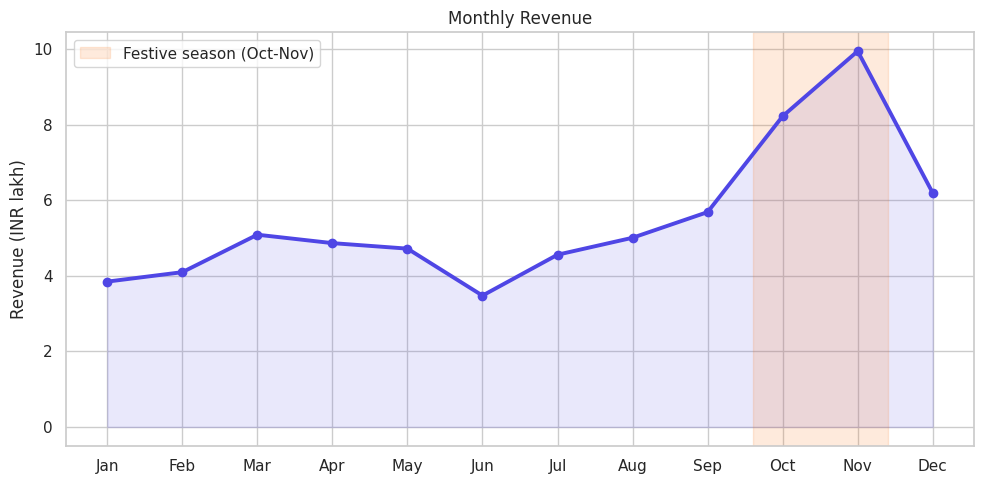

In [15]:
# 4.1 Trend: monthly revenue
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = df.groupby("month")["revenue"].sum().reindex(range(1, 13))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(months, monthly.values / 1e5, marker="o", lw=2.8, color=PRIMARY)
ax.fill_between(range(12), monthly.values / 1e5, alpha=0.12, color=PRIMARY)
ax.axvspan(8.6, 10.4, color=ACCENT, alpha=0.15, label="Festive season (Oct-Nov)")
ax.set(title="Monthly Revenue", ylabel="Revenue (INR lakh)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "01_monthly_revenue.png", dpi=150); plt.show()

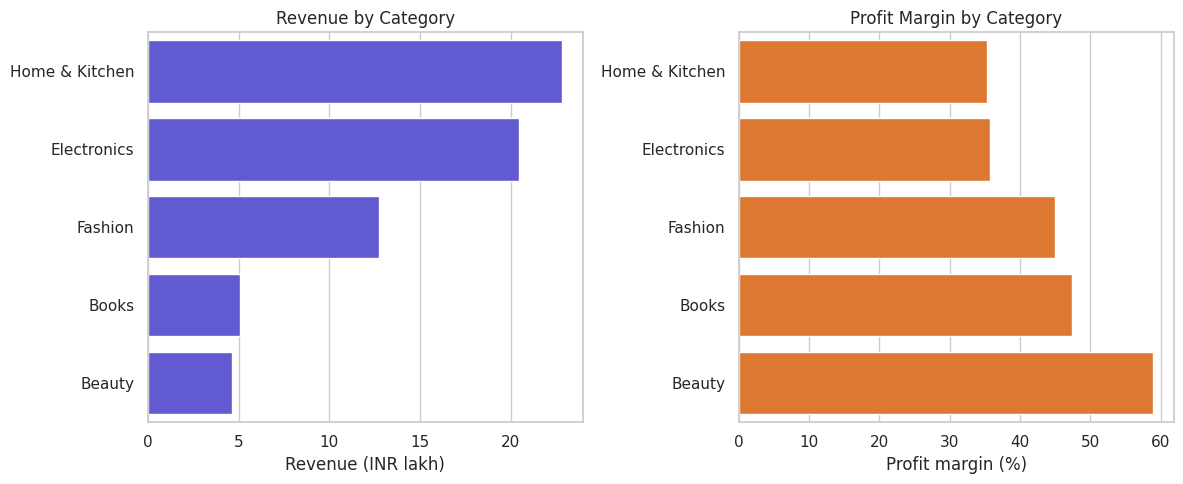

In [16]:
# 4.2 Comparison: revenue and margin by category
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
order = by_category.index
sns.barplot(x=by_category["revenue"] / 1e5, y=order, color=PRIMARY, ax=axes[0])
axes[0].set(title="Revenue by Category", xlabel="Revenue (INR lakh)", ylabel="")
sns.barplot(x=by_category["margin_pct"], y=order, color=ACCENT, ax=axes[1])
axes[1].set(title="Profit Margin by Category", xlabel="Profit margin (%)", ylabel="")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_category_revenue_margin.png", dpi=150); plt.show()

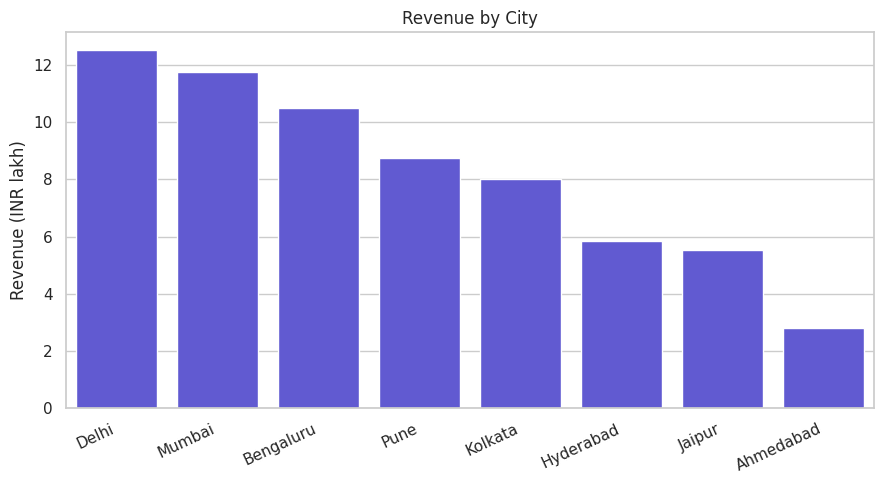

In [17]:
# 4.3 Comparison: revenue by city
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=by_city.index, y=by_city["revenue"] / 1e5, color=PRIMARY, ax=ax)
ax.set(title="Revenue by City", xlabel="", ylabel="Revenue (INR lakh)")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_city_revenue.png", dpi=150); plt.show()

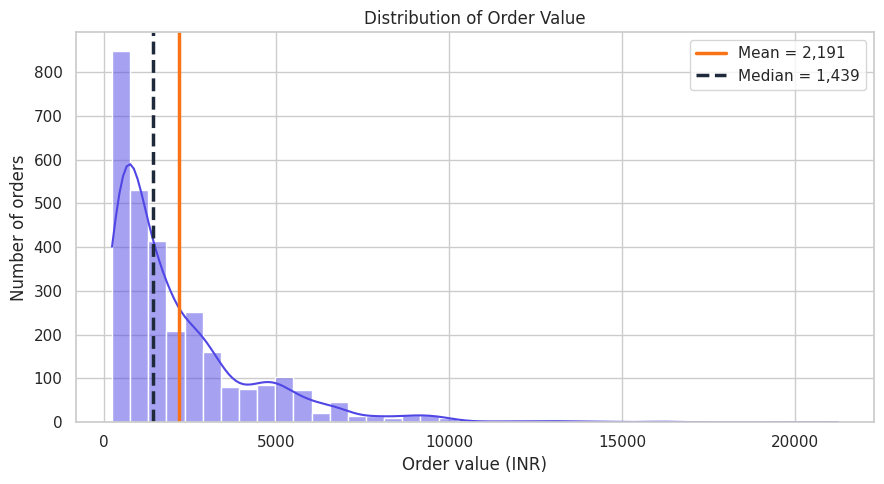

In [18]:
# 4.4 Distribution: order value
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["revenue"], bins=40, kde=True, color=PRIMARY, ax=ax)
ax.axvline(df["revenue"].mean(), color=ACCENT, lw=2.5, label=f"Mean = {df['revenue'].mean():,.0f}")
ax.axvline(df["revenue"].median(), color=DARK, lw=2.5, ls="--", label=f"Median = {df['revenue'].median():,.0f}")
ax.set(title="Distribution of Order Value", xlabel="Order value (INR)", ylabel="Number of orders")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "04_order_value_distribution.png", dpi=150); plt.show()

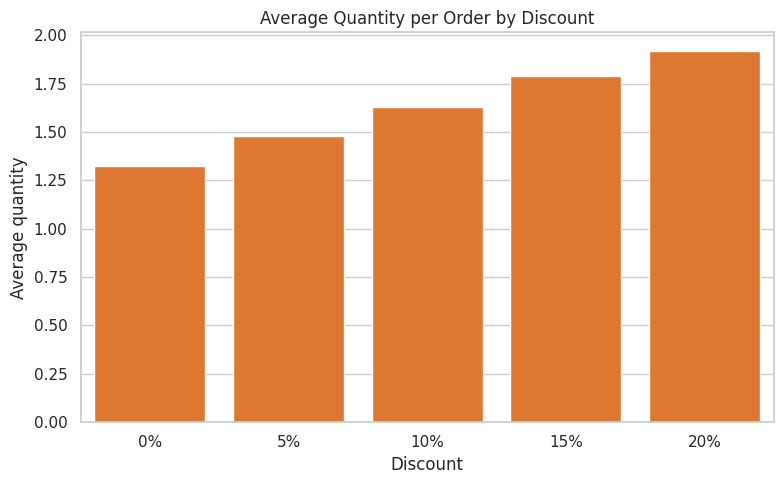

In [19]:
# 4.5 Relationship: does a bigger discount lead to bigger baskets?
qty_by_discount = df.groupby("discount_pct")["quantity"].mean()
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=qty_by_discount.index.astype(str) + "%", y=qty_by_discount.values, color=ACCENT, ax=ax)
ax.set(title="Average Quantity per Order by Discount", xlabel="Discount", ylabel="Average quantity")
fig.tight_layout(); fig.savefig(FIG_DIR / "05_discount_vs_quantity.png", dpi=150); plt.show()

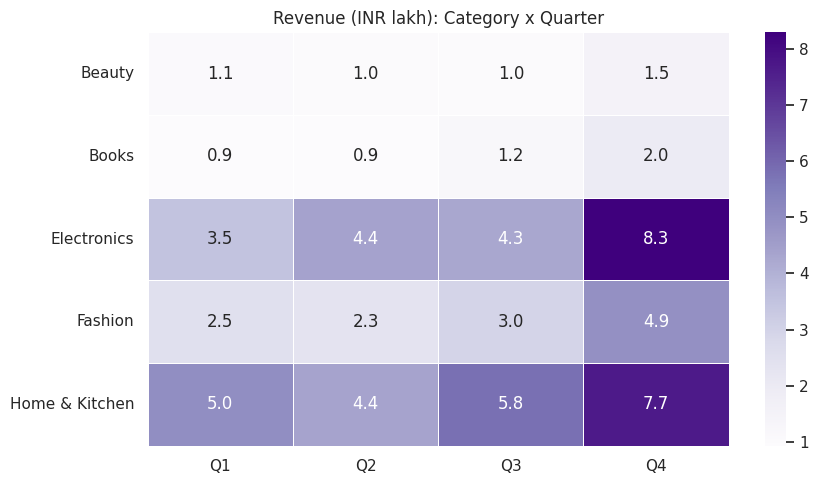

In [20]:
# 4.6 Two categories at once: category x quarter heatmap
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot.drop(index="Total", columns="Total") / 1e5, annot=True, fmt=".1f", cmap="Purples", linewidths=0.5, ax=ax)
ax.set(title="Revenue (INR lakh): Category x Quarter", xlabel="", ylabel="")
fig.tight_layout(); fig.savefig(FIG_DIR / "06_category_quarter_heatmap.png", dpi=150); plt.show()

## 5. Basic analysis
### 5.1 Summary statistics

In [21]:
df[["quantity", "discount_pct", "revenue", "profit"]].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,"3,000.00",1.57,0.77,1.00,1.00,1.00,2.00,6.00
discount_pct,"3,000.00",8.09,6.84,0.00,0.00,10.00,15.00,20.00
revenue,"3,000.00","2,190.51","2,189.13",239.20,718.40,"1,439.10","2,848.10","21,245.75"
profit,"3,000.00",874.48,712.19,119.20,359.10,649.00,"1,134.05","7,596.00"


### 5.2 Correlation
**Reading it:** r near +1 means both rise together, near 0 means no linear link, near -1 means one rises as the other falls. Correlation is not causation.

In [22]:
corr = df[["quantity", "discount_pct", "revenue", "profit", "age"]].corr()
print(f"Discount vs quantity : r = {corr.loc['discount_pct', 'quantity']:.3f}")
print(f"Discount vs revenue  : r = {corr.loc['discount_pct', 'revenue']:.3f}")
print(f"Quantity vs revenue  : r = {corr.loc['quantity', 'revenue']:.3f}")
corr

Discount vs quantity : r = 0.271
Discount vs revenue  : r = 0.063
Quantity vs revenue  : r = 0.447


,quantity,discount_pct,revenue,profit,age
quantity,1.00,0.27,0.45,0.50,0.01
discount_pct,0.27,1.00,0.06,-0.07,0.01
revenue,0.45,0.06,1.00,0.96,0.02
profit,0.50,-0.07,0.96,1.00,0.02
age,0.01,0.01,0.02,0.02,1.00


### 5.3 Key business metrics and insights

In [23]:
total_rev, total_profit = df["revenue"].sum(), df["profit"].sum()
festive_share = df.loc[df["month"].isin([10, 11]), "revenue"].sum() / total_rev * 100
best_month = monthly.idxmax()
top_cat = by_category.index[0]
top_city = by_city.index[0]
best_margin_cat = by_category["margin_pct"].idxmax()
platinum_share = tier_summary.loc["Platinum", "share_of_revenue_%"]

results.update({
    "total_revenue": float(total_rev), "total_profit": float(total_profit),
    "profit_margin_pct": float(total_profit / total_rev * 100),
    "avg_order_value": float(df["revenue"].mean()), "median_order_value": float(df["revenue"].median()),
    "top_category": top_cat, "top_category_revenue": float(by_category.loc[top_cat, "revenue"]),
    "top_category_share_pct": float(by_category.loc[top_cat, "revenue"] / total_rev * 100),
    "best_margin_category": best_margin_cat, "best_margin_pct": float(by_category.loc[best_margin_cat, "margin_pct"]),
    "lowest_margin_category": by_category["margin_pct"].idxmin(), "lowest_margin_pct": float(by_category["margin_pct"].min()),
    "top_city": top_city, "top_city_revenue": float(by_city.loc[top_city, "revenue"]),
    "best_month": months[best_month - 1], "festive_share_pct": float(festive_share),
    "corr_discount_quantity": float(corr.loc["discount_pct", "quantity"]),
    "corr_discount_revenue": float(corr.loc["discount_pct", "revenue"]),
    "corr_quantity_revenue": float(corr.loc["quantity", "revenue"]),
    "qty_by_discount": {f"{k}%": float(v) for k, v in qty_by_discount.items()},
    "payment_share": {k: float(v) for k, v in payment_share.items()},
    "platinum_customers": int(tier_summary.loc["Platinum", "customers"]),
    "platinum_revenue_share_pct": float(platinum_share),
    "revenue_by_category": {k: float(v) for k, v in by_category["revenue"].items()},
    "margin_by_category": {k: float(v) for k, v in by_category["margin_pct"].items()},
    "n_customers": int(cust.shape[0]),
})

print(f"1. Total revenue       : INR {total_rev:,.0f}  | profit margin {total_profit / total_rev:.1%}")
print(f"2. Average order value : INR {df['revenue'].mean():,.0f}  (median INR {df['revenue'].median():,.0f})")
print(f"3. Top category        : {top_cat} ({results['top_category_share_pct']:.1f}% of revenue)")
print(f"4. Best-margin category: {best_margin_cat} ({results['best_margin_pct']:.1f}%)")
print(f"5. Top city            : {top_city}")
print(f"6. Best month          : {results['best_month']} | Oct-Nov festive share: {festive_share:.1f}%")
print(f"7. Discount vs quantity: r = {results['corr_discount_quantity']:.2f} (weak positive)")
print(f"8. Platinum tier       : {results['platinum_customers']} customers = {platinum_share:.1f}% of revenue")

1. Total revenue       : INR 6,571,541  | profit margin 39.9%
2. Average order value : INR 2,191  (median INR 1,439)
3. Top category        : Home & Kitchen (34.7% of revenue)
4. Best-margin category: Beauty (59.0%)
5. Top city            : Delhi
6. Best month          : Nov | Oct-Nov festive share: 27.7%
7. Discount vs quantity: r = 0.27 (weak positive)
8. Platinum tier       : 60 customers = 28.1% of revenue


### 5.4 Statistical choices explained
A result is only convincing when the **method** is justified. For each question below, the choice of technique and the reason for it are written next to the code.

In [24]:
from scipy import stats

# --- Choice 1: Pearson AND Spearman correlation -------------------------------------
# Pearson measures LINEAR association but is sensitive to outliers. Spearman works on ranks,
# so it is robust to skewed data. If both agree, the relationship is trustworthy.
pear_r, pear_p = stats.pearsonr(df["discount_pct"], df["quantity"])
spear_r, spear_p = stats.spearmanr(df["discount_pct"], df["quantity"])
_, disc_rev_p = stats.pearsonr(df["discount_pct"], df["revenue"])
print(f"Discount vs quantity | Pearson r = {pear_r:.3f} (p = {pear_p:.1e}) | Spearman rho = {spear_r:.3f} (p = {spear_p:.1e})")
print(f"Discount vs revenue  | Pearson r = {df['discount_pct'].corr(df['revenue']):.3f} (p = {disc_rev_p:.3f})")

# --- Choice 2: bootstrap confidence interval for the MEAN order value ---------------
# Order value is right-skewed (see the histogram), so the usual normal-theory interval is less
# reliable. The bootstrap re-samples our own data 5,000 times and needs no normality assumption.
rng = np.random.default_rng(42)
values = df["revenue"].to_numpy()
boot_means = [rng.choice(values, size=len(values), replace=True).mean() for _ in range(5000)]
ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
print(f"Mean order value = {values.mean():,.0f} | 95% bootstrap CI = ({ci_low:,.0f}, {ci_high:,.0f})")

# --- Choice 3: Welch t-test + Cohen's d + Mann-Whitney U ----------------------------
# Question: do high-discount orders (>= 15%) contain more items than low-discount orders (<= 5%)?
# Welch's t-test does not assume equal variances. A p-value only says "is there a difference?",
# so Cohen's d is added to say "how big is it?". Quantity is a skewed count, so the rank-based
# Mann-Whitney U test is run as a robustness check.
low_q = df.loc[df["discount_pct"] <= 5, "quantity"]
high_q = df.loc[df["discount_pct"] >= 15, "quantity"]
t_stat, t_p = stats.ttest_ind(high_q, low_q, equal_var=False)
pooled_sd = np.sqrt((high_q.var(ddof=1) + low_q.var(ddof=1)) / 2)
cohens_d = (high_q.mean() - low_q.mean()) / pooled_sd
_, mw_p = stats.mannwhitneyu(high_q, low_q, alternative="two-sided")
print(f"Mean quantity: high discount = {high_q.mean():.2f}, low discount = {low_q.mean():.2f}")
print(f"Welch t = {t_stat:.2f}, p = {t_p:.1e} | Cohen's d = {cohens_d:.2f} | Mann-Whitney p = {mw_p:.1e}")

# --- Choice 4: median and IQR for skewed variables ----------------------------------
q1, q3 = df["revenue"].quantile([0.25, 0.75])
iqr_outliers = int(((df["revenue"] < q1 - 1.5 * (q3 - q1)) | (df["revenue"] > q3 + 1.5 * (q3 - q1))).sum())
print(f"Revenue skewness = {df['revenue'].skew():.2f} | IQR-rule outliers = {iqr_outliers} (kept: large orders are genuine)")

results.update({
    "pearson_r": float(pear_r), "pearson_p": float(pear_p), "spearman_rho": float(spear_r), "spearman_p": float(spear_p),
    "disc_rev_p": float(disc_rev_p), "boot_ci_low": float(ci_low), "boot_ci_high": float(ci_high),
    "low_disc_qty": float(low_q.mean()), "high_disc_qty": float(high_q.mean()), "n_low": int(len(low_q)), "n_high": int(len(high_q)),
    "ttest_t": float(t_stat), "ttest_p": float(t_p), "cohens_d": float(cohens_d), "mw_p": float(mw_p),
    "revenue_skew": float(df["revenue"].skew()), "revenue_outliers_iqr": iqr_outliers,
})

Discount vs quantity | Pearson r = 0.271 (p = 1.2e-51) | Spearman rho = 0.265 (p = 2.8e-49)
Discount vs revenue  | Pearson r = 0.063 (p = 0.001)
Mean order value = 2,191 | 95% bootstrap CI = (2,115, 2,268)
Mean quantity: high discount = 1.85, low discount = 1.38
Welch t = 13.35, p = 4.0e-38 | Cohen's d = 0.61 | Mann-Whitney p = 2.7e-41
Revenue skewness = 2.32 | IQR-rule outliers = 172 (kept: large orders are genuine)


### 5.5 Limitations and potential biases of this dataset
Because the data is **synthetic**, it carries biases that real data would not, and it is important to state them honestly.

| Limitation / bias | What it means here | Effect on conclusions |
|---|---|---|
| **Built-in assumptions (circularity)** | The generator itself contains a festive-season boost and a discount-to-quantity link | The analysis *recovers* these patterns; it does not *discover* them. It proves the pipeline works, not that the business behaves this way |
| **Simplified randomness** | Customers and products are picked uniformly at random | Real shoppers repeat favourite products and have habits, so real data has more structure |
| **Arbitrary proportions** | City shares, payment shares and discount frequencies were chosen by me | Rankings such as "top city" mirror my settings, not real demand |
| **Single year, fixed prices** | Only 2025 is covered; prices and costs never change | No year-on-year trend, inflation or price changes can be studied |
| **Missing real-world events** | No returns, cancellations, stock-outs, fraud or customer reviews | Revenue and profit are overstated compared with a real business |
| **Artificial mess** | Duplicates, missing ages and spelling errors were injected at random | Real missing data is rarely random (for example, certain groups skip the age field), so median filling would be riskier in reality |
| **Small, clean sample** | 3,000 orders and 400 customers with no extreme outliers | Statistical tests become "significant" easily; real effects are usually weaker and noisier |
| **Correlation is not causation** | Discounts and quantity move together here | Even in real data, other factors (festivals, stock levels) could explain the link |

**How these biases would be reduced with real data:** use an actual transaction export, check *why* values are missing before imputing, compare several years, and validate findings on a hold-out period.

In [25]:
with open("outputs/results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved outputs/results.json")

Saved outputs/results.json


## 6. Conclusion

- **Setup:** the environment is documented and reproducible (versions printed, `requirements.txt` provided).
- **Manipulation:** the data was cleaned, merged (with join validation), enriched with new columns, filtered, grouped and pivoted.
- **Visualization:** six charts, each chosen to match its question.
- **Analysis:** summary statistics, correlation and business metrics turned raw rows into insights.

**Limitation:** the data is synthetic and contains built-in assumptions, so the insights show that the *method* works but must not be treated as facts about a real business (see section 5.5).